# NPUWattch hands-on — 2. PyTorchSim: more workloads on the TPU-like NPU

Notebook 1 ran one matmul. This notebook runs the other PyTorchSim workloads
of the tutorial on the same TPUv3-like NPU (two 128×128 systolic arrays, 128
VPU lanes with 16 MB of scratchpads, 16 HBM2 channels). All runs are float32, because
PyTorchSim simulates float32 kernels only.

The point of each section is not the number but the reason for it. For every
workload we ask three questions: which part of the hardware does the work,
which simulator counter NPUWattch charges it from, and where in the report
you can see it.

```
pytorchsim/tpu_like_fp32/
├── compound_components.yaml, projection.yaml, user_components.yaml   the hardware model (shared)
├── matmul_1024/                       the 1024^3 matmul of notebook 1
├── matmul_train/                      forward + backward of the 1024^3 matmul (3 kernels)
├── matmul_2048_1core/                 one 2048^3 matmul on 1 core
├── matmul_2048_2core/                 the same matmul on 2 cores (a different PyTorchSim config)
├── softmax/                           softmax and exp2 on a 1024×1024 tensor: no MAC at all
├── resnet50/                          the 7 ResNet-50 layers of the Timeloop example, plus ReLU and batch norm
├── llama3_8b/{prefill,decode}/        one Llama-3-8B decoder block, T=512 and T=1
├── gemma2_9b/{prefill,decode}/        one Gemma-2-9B decoder block
└── deepseek_v2_lite/{prefill,decode}/ one DeepSeek-V2-Lite MoE decoder block
```

Each workload folder is one PyTorchSim run root: `config.yml`,
`togsim_results/`, `outputs/`, `booksim2_config/`, and `kernels.yaml`, which
names the kernels. Its `run` script points at the hardware model in the
design folder with `--compound-components ../compound_components.yaml` and
the two other definition flags. `how_the_data_was_made/` holds the PyTorch
script and the run manifest.

In [1]:
import sys; sys.path.insert(0, ".")
from tutorial_helpers import *
import pandas as pd, re
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
print("npuwattch:", npuwattch_binary())


def window_components(rep, label, top=None):
    """The per-component energy of one window, from report.json (all rows, in tree order)."""
    labels = [w["label"] for w in rep["windows"]]
    i = labels.index(label)
    rows = [{"component": r["name"], "energy": r["cells"][i]}
            for r in rep["matrix"]["rows"] if r["cells"][i] != "—"]
    df = pd.DataFrame(rows)
    return df.head(top) if top else df


def occupancy_table(text, names):
    """The useful MACs and the active PE cycles of each GEMM kernel (NW-6222), with its name."""
    rows = []
    for _, code_, line in messages(text):
        if code_ != "NW-6222":
            continue
        m = re.search(r": (\w+): (\d+) useful MACs of (\d+) active PE cycles \(([\d.]+)%\)", line)
        rows.append({"kernel": names.get(m.group(1), m.group(1)), "useful MACs": int(m.group(2)),
                     "active PE cycles": int(m.group(3)), "occupancy %": float(m.group(4))})
    return pd.DataFrame(rows)


def kernel_names(example_dir):
    """hash -> name from kernels.yaml (the first name of each hash)."""
    names = {}
    for line in (example_dir / "kernels.yaml").read_text().splitlines():
        m = re.search(r"name: ([^,]+), hash: (\w+)", line)
        if m and m.group(2) not in names:
            names[m.group(2)] = m.group(1)
    return names

npuwattch: /home/KNUEEhdd1/ys_knu/kmk/miniforge3/envs/npuwattch/bin/npuwattch


## 1. Run them all

Each run takes a few seconds. We keep the console text and the report of
each run.

In [2]:
WORKLOADS = {
    "matmul 1024³ (nb 1)":      "pytorchsim/tpu_like_fp32/matmul_1024",
    "matmul train":             "pytorchsim/tpu_like_fp32/matmul_train",
    "matmul 2048³ 1 core":      "pytorchsim/tpu_like_fp32/matmul_2048_1core",
    "matmul 2048³ 2 cores":     "pytorchsim/tpu_like_fp32/matmul_2048_2core",
    "softmax + exp2":           "pytorchsim/tpu_like_fp32/softmax",
    "ResNet-50":                "pytorchsim/tpu_like_fp32/resnet50",
    "Llama-3-8B prefill":       "pytorchsim/tpu_like_fp32/llama3_8b/prefill",
    "Llama-3-8B decode":        "pytorchsim/tpu_like_fp32/llama3_8b/decode",
    "Gemma-2-9B prefill":       "pytorchsim/tpu_like_fp32/gemma2_9b/prefill",
    "Gemma-2-9B decode":        "pytorchsim/tpu_like_fp32/gemma2_9b/decode",
    "DeepSeek-V2-Lite prefill": "pytorchsim/tpu_like_fp32/deepseek_v2_lite/prefill",
    "DeepSeek-V2-Lite decode":  "pytorchsim/tpu_like_fp32/deepseek_v2_lite/decode",
}
texts, reps = {}, {}
for label, path in WORKLOADS.items():
    if not (example(path) / "run").exists():
        print(f"{label:28s} (folder not present, skipped)")
        continue
    texts[label] = run(example(path))
    reps[label] = report(example(path))
    print(f"{label:28s} {reps[label]['totals']['energy_str']:>12s}   {len(reps[label]['windows']):2d} windows")

matmul 1024³ (nb 1)           5.98e+03 µJ    1 windows


matmul train                   1.8e+04 µJ    3 windows


matmul 2048³ 1 core           4.79e+04 µJ    1 windows


matmul 2048³ 2 cores          4.76e+04 µJ    1 windows


softmax + exp2                1.16e+03 µJ    4 windows


...

Llama-3-8B decode             4.29e+04 µJ   13 windows


Gemma-2-9B prefill            6.72e+05 µJ   13 windows


Gemma-2-9B decode             3.85e+04 µJ   13 windows


DeepSeek-V2-Lite prefill      3.37e+05 µJ   17 windows


DeepSeek-V2-Lite decode       1.43e+04 µJ   17 windows


In [3]:
def row(label, rep):
    r = summary_row(rep, label)
    e = rep.get("efficiency") or {}
    r["cycles"] = sum(w["cycles"] for w in rep["windows"])
    r["pJ / FLOP"] = e.get("pJ_per_flop_str")
    return r
summary = pd.DataFrame([row(k, v) for k, v in reps.items()])
display(summary.drop(columns=["total_pJ"]))

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC,cycles,pJ / FLOP
0,matmul 1024³ (nb 1),5.98e+03 µJ,8.1,53.197,108 W,5.57,52022,2.78 pJ/FLOP
1,matmul train,1.8e+04 µJ,8.6,53.197,108 W,5.60,156967,2.8 pJ/FLOP
2,matmul 2048³ 1 core,4.79e+04 µJ,8.2,53.197,143 W,5.57,313749,2.79 pJ/FLOP
3,matmul 2048³ 2 cores,4.76e+04 µJ,7.7,106.437,264 W,5.55,169707,2.77 pJ/FLOP
4,softmax + exp2,1.16e+03 µJ,83.1,53.197,10 W,117.40,108464,58.7 pJ/FLOP
5,ResNet-50,6.1e+03 µJ,46.0,53.197,10.8 W,11.46,531107,5.73 pJ/FLOP
6,Llama-3-8B prefill,6.66e+05 µJ,12.1,53.197,88.3 W,5.85,7092273,2.92 pJ/FLOP
7,Llama-3-8B decode,4.29e+04 µJ,90.7,53.197,10.7 W,192.45,3767418,96.2 pJ/FLOP
8,Gemma-2-9B prefill,6.72e+05 µJ,20.1,53.197,60.9 W,6.48,10380799,3.24 pJ/FLOP
9,Gemma-2-9B decode,3.85e+04 µJ,90.8,53.197,12.5 W,189.65,2889091,94.8 pJ/FLOP


Keep the matmul of notebook 1 as the reference: 6.0 mJ, 2.8 pJ/FLOP, the
systolic arrays at 91% of the energy and DRAM at 8%. That is what this NPU
looks like when every PE does a useful MAC every active cycle and every
byte from DRAM is reused 1024 times. Every workload below departs from that
picture in its own way, and the departure is always visible in one of three
places: the per-kernel table, the per-component table, or the messages.

A word on `pJ / MAC` in the table. NPUWattch counts the useful MACs of each
GEMM kernel from the operator and its tensor shapes (`INFO NW-6222`), so
this column is energy per *useful* MAC, with DRAM included. A kernel whose
PEs sit empty gets a higher value. The empty PEs are clock-gated and cost
leakage only, but the data movement and the time of the kernel are divided
by fewer useful MACs. For a run with no GEMM at all (`softmax + exp2`), the
column counts the vector-unit operations instead, so it is not a MAC cost.

## 2. Training: the backward pass is two more matmuls

`matmul_train` runs `c = a @ b` and then `c.sum().backward()`. PyTorchSim
compiles the backward pass into two kernels, `grad_a = g @ bᵀ` and
`grad_b = aᵀ @ g`. The windows are named in `kernels.yaml`.

In [4]:
show_file(example("pytorchsim/tpu_like_fp32/matmul_train/kernels.yaml"))
display(windows_df(reps["matmul train"]))

- {name: fwd, hash: fqywo6ndalo, log: 000_fwd__20261010_081119_c30c29e0.log, cycles: 52058, wall_s: 95.2}
- {name: grad_b, hash: x5ej34kmf2v, log: 001_grad_b__20261010_081350_256e4b4c.log, cycles: 52848, wall_s: 185.7}
- {name: grad_a, hash: 2qor5t5rutd, log: 002_grad_a__20261010_081425_22b9a7c6.log, cycles: 52061, wall_s: 185.7}


,window,cycles,dynamic,leakage,total,total_pJ
0,fwd,52058,5.97e+03 µJ,9.8 µJ,5.98e+03 µJ,5.980576e+09
1,grad_b,52848,6.02e+03 µJ,9.95 µJ,6.03e+03 µJ,6.034704e+09
2,grad_a,52061,6.02e+03 µJ,9.8 µJ,6.03e+03 µJ,6.028862e+09


**Why three windows of the same size.** A gradient of a matmul is a matmul
of the same three dimensions, so each backward kernel has the same 1.07 G
MACs, the same 128×128 weight tiles, and the same number of input rows. The
systolic array is weight-stationary: its energy is the MAC count times the
energy of one `hold_b` operation plus the weight loads, and none of these
depend on which operand is transposed. The small difference (5.96, 6.02,
6.01 mJ) is DRAM: a transposed operand changes the row-buffer locality of
the HBM, which the `activate` share of the DRAM breakdown shows.

**What this means for training energy.** With this machine model, one
training step of a dense layer costs three times its forward pass before
the optimizer runs. The cost of the backward pass is a MAC-count argument,
not a hardware one.

## 3. One core or two: where does the energy go?

The ISPASS PyTorchSim tutorial shows that a 2048³ matmul finishes in about
half the cycles on two cores. NPUWattch shows what that costs. The 2-core
run uses PyTorchSim's `systolic_ws_128x128_c2_booksim_tpuv3.yml` config: two
cores, 32 HBM channels, and a 64-port NoC (32 core ports and 32 memory
ports). NPUWattch rebuilds the larger
machine from the log header, so the two runs share one hardware model.

In [5]:
one, two = reps["matmul 2048³ 1 core"], reps["matmul 2048³ 2 cores"]
pd.DataFrame([
    {"run": "1 core", "cycles": one["windows"][0]["cycles"], "total": one["totals"]["energy_str"],
     "leakage": one["totals"]["leak_str"], "DRAM %": round(one["npu_dram_split"]["dram_pct"], 1),
     "area mm²": round(one["totals"]["area_mm2"], 1), "avg power": one["totals"]["avg_power_str"]},
    {"run": "2 cores", "cycles": two["windows"][0]["cycles"], "total": two["totals"]["energy_str"],
     "leakage": two["totals"]["leak_str"], "DRAM %": round(two["npu_dram_split"]["dram_pct"], 1),
     "area mm²": round(two["totals"]["area_mm2"], 1), "avg power": two["totals"]["avg_power_str"]},
])

,run,cycles,total,leakage,DRAM %,area mm²,avg power
0,1 core,313749,4.79e+04 µJ,59 µJ,8.2,53.2,143 W
1,2 cores,169707,4.76e+04 µJ,63.9 µJ,7.7,106.4,264 W


In [6]:
cmp = pd.merge(components_df(one)[["component", "energy"]], components_df(two)[["component", "energy"]],
               on="component", how="outer", suffixes=(" 1 core", " 2 cores"))
display(cmp[cmp["component"].str.contains("pe|dram|icnt|vpu_spad|w_reg", regex=True)].fillna("—"))
show_tree(texts["matmul 2048³ 2 cores"])

,component,energy 1 core,energy 2 cores
0,core0.array0.pe,2.17e+04 µJ,1.09e+04 µJ
1,core0.array0.w_reg,1.22 µJ,639 nJ
2,core0.array1.pe,2.17e+04 µJ,1.09e+04 µJ
3,core0.array1.w_reg,1.22 µJ,639 nJ
6,core0.sfu_pipe,176 nJ,95.5 nJ
8,core0.vpu_spad,326 µJ,164 µJ
10,core1.array0.pe,—,1.09e+04 µJ
11,core1.array0.w_reg,—,639 nJ
12,core1.array1.pe,—,1.09e+04 µJ
13,core1.array1.w_reg,—,639 nJ


INFO (NW-1001): Instance hierarchy (reconstructed from the run's model):
chip
├── core0
│   ├── array0
│   │   ├── pe [×16384]  (class: fpmac, exponent_bits=8, mantissa_bits=23, pipeline_stages=4)
│   │   └── w_reg [×16384]  (class: register_file, data_width=32, mem_depth_per_bank=1 = 4 B)
│   ├── array1
│   │   ├── pe [×16384]  (class: fpmac, exponent_bits=8, mantissa_bits=23, pipeline_stages=4)
│   │   └── w_reg [×16384]  (class: register_file, data_width=32, mem_depth_per_bank=1 = 4 B)
│   ├── vpu_spad [×128]  (class: sram, mem_template=sram_256k, mem_banks=1, mem_depth_per_bank=8192, data_width=128 = 128 KB)
│   ├── vrf [×128]  (class: register_file, data_width=256, mem_depth_per_bank=32 = 1 KB)
│   ├── vfu [×128]  (class: fpmac, exponent_bits=8, mantissa_bits=23, pipeline_stages=4)
│   ├── dma_q  (class: fifo)
│   ├── dma_addr  (class: intadd)
│   └── sfu_pipe [×128]  (class: fpsfu)
├── core1
│   ├── array0
│   │   ├── pe [×16384]  (class: fpmac, exponent_bits=8, mantissa_bits=23,

**Why the energy stays the same.** Dynamic energy is work times energy per
operation. The second core does not change the work: 8.6 G MACs, the same
weight tiles, the same bytes from DRAM. Each core's arrays do half of the
MACs (`core0.array0.pe` falls to half, `core1.array0.pe` takes the other
half), so the sum is unchanged: 47.9 mJ on one core, 47.6 mJ on two.

**Why the leakage is almost unchanged too.** Leakage is power times time.
The chip has twice the transistors (106.4 mm² against 53.2), but it runs for
0.54 of the time. Twice the leakage power for half the time is the same
leakage energy. The average power goes from 143 W to 264 W (1.84×, close to
the ratio of the cycle counts), which is what a data center sees on its
meter. For a TDP budget, the second core costs as much as the first one.

**What does change.** The 32-channel HBM moves the same bytes over twice
the channels, so the DRAM share drops a little (8.2 → 7.7%): fewer row
activations per channel. The NoC is a 64-port crossbar instead of 32 ports,
and the crossbar model is extrapolated beyond its characterized 32 ports
(`NW-8111`), so the `icnt_xbar` line grows. Both are small next to the
arrays. In short: two cores buy time, not energy.

## 4. A kernel with no MAC: softmax

`softmax` runs `torch.softmax(x, dim=-1)` and `torch.exp2(x)` on a
1024×1024 tensor. PyTorchSim compiles the softmax into three kernels: a row
maximum, an exp-and-sum, and the division. None of them uses the systolic
array.

In [7]:
display(windows_df(reps["softmax + exp2"]))
display(components_df(reps["softmax + exp2"], top=8))
show_messages(texts["softmax + exp2"], codes=["NW-6201", "NW-6208", "NW-6002"])

,window,cycles,dynamic,leakage,total,total_pJ
0,01_softmax_p0,14102,185 µJ,2.65 µJ,188 µJ,1.876072e+08
1,01_softmax_p1,15224,199 µJ,2.86 µJ,202 µJ,2.023419e+08
2,01_softmax_p2,26837,373 µJ,5.05 µJ,378 µJ,3.776687e+08
3,02_exp2,52301,379 µJ,9.84 µJ,389 µJ,3.891880e+08


,component,class,model,instances,energy,share %,area
0,dram_chan,hbm,const,16,962 µJ,83.1,n/a
1,core0.vfu,fpmac,cal,128,61.6 µJ,5.3,483
2,icnt_buf,sram,cal,32,34.7 µJ,3.0,1.74e+04
3,core0.vrf,regfile,cal,128,31.2 µJ,2.7,4.16e+03
4,core0.sfu_pipe,fpsfu,cal,128,24.5 µJ,2.1,997
5,core0.vpu_spad,sram,cal,128,22.1 µJ,1.9,2.78e+05
6,icnt_xbar,crossbar,cal,1,5.66 µJ,0.5,1.84e+04
7,core0.array1.pe,fpmac,cal,16384,4.49 µJ,0.4,483


WARNING (NW-6201): ki6yhkrcpgm: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6201): oqy5oqtice5: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6208): oqy5oqtice5: the kernel has SFU operations and an unknown operand dtype, so NPUWattch charges the SFU at fp32.
WARNING (NW-6201): snq4z7o7dnb: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6208): snq4z7o7dnb: the kernel has SFU operations and an unknown operand dtype, so NPUWattch charges the SFU at fp32.
WARNING (NW-6201): 7ocdaitk5yp: the kernel has no linalg.matmul, so it has no MAC configuration.
WARNING (NW-6208): 7ocdaitk5yp: the kernel has SFU operations and an unknown operand dtype, so NPUWattch charges the SFU at fp32.
WARNING (NW-6002): The run has no MAC kernel, so non-MAC kernels use an fp32 datapath.


**Why the vector datapath leads on chip, and the register file is small.**
After DRAM, the largest line is `vfu` (5.3% of the run): the SIMD datapath
of the 128 lanes, which does the arithmetic around each exponent. NPUWattch
charges one datapath operation per lane in each active cycle of the vector
unit. The register file (`vrf`, 2.7%) is small, because with clock gating an
access costs only its per-access energy: 0.85 pJ for a 256-bit read and
1.41 pJ for a write. The register-file model is extrapolated to the 256-bit
width (`NW-8111`), so treat its share as an estimate. The exponent itself
goes to the SFU (`sfu_pipe`, 2.1%): one SFU operation per element, 8.1 µJ
for each pass over the 1 M elements. The elements of one SFU instruction
come from the vector type in the kernel MLIR (`NW-6225`).

**Why DRAM is most of the energy.** DRAM is 83% of this run. The three
softmax kernels each stream the whole 4 MB tensor from DRAM: the maximum
reads it once, the exp-and-sum reads it again, and the division reads it a
third time and writes the result. Nothing is reused on chip between
kernels, because PyTorchSim compiles each one separately, so DRAM is 672 µJ
of the 768 µJ of the three softmax kernels (88%). A fused softmax would read
the tensor once.

**Why `exp2` alone costs about half as much as the three softmax kernels.**
It is one pass over DRAM (290 µJ against 672 µJ for the softmax), and it
costs 389 µJ in total. But its vector unit is active for 52 000 cycles
against 12 000 for the division kernel: the compiler lowers `exp2` to
`exp(x·ln 2)` with extra vector instructions per element. So the `vfu`
(41.5 µJ) and the `vrf` (20.7 µJ) of `exp2` are about twice those of the
three softmax kernels together (20.0 µJ and 10.0 µJ). The lesson is the
same from both sides: for elementwise kernels, data movement decides, and
the instructions the compiler emits set the on-chip part.

**Why there is no PE energy at all.** The arrays are gated: the compound's
`default_mode: gated` means an element that no action names costs only its
leakage. Each window is marked `non_mac`, and because this run has no GEMM
kernel to borrow a data type from, NPUWattch charges the SFU at fp32 and
says so (`NW-6002`, `NW-6208`). The simulator ran float32, so that is the
right choice here.

## 5. ResNet-50: the same seven layers as the Timeloop example

`resnet50` runs the seven layers of `timeloop/gemmini_like/resnet50` as
`F.conv2d` and one matmul, batch 1, plus a ReLU and a batch norm. PyTorchSim
compiles each convolution into one or two layout kernels (they pad the
input, or re-lay the weights, as `06_res5_3x3_p1` does) and the GEMM, which
is the last kernel of the layer. The window names come from `kernels.yaml`.

In [8]:
rep_r = reps["ResNet-50"]; ex_r = example("pytorchsim/tpu_like_fp32/resnet50")
w = windows_df(rep_r)
display(w)
gemm = w[w["window"].str.contains(r"_p[12]$|07_fc", regex=True) & ~w["window"].str.contains("_p0|_p1$", regex=True)]
occ = occupancy_table(texts["ResNet-50"], kernel_names(ex_r))
occ["pJ per useful MAC"] = [round(float(w.set_index("window").loc[k, "total_pJ"]) / m, 1)
                           for k, m in zip(occ["kernel"], occ["useful MACs"])]
display(occ)

,window,cycles,dynamic,leakage,total,total_pJ
0,01_conv1_p0,4458,39.8 µJ,839 nJ,40.7 µJ,4.068159e+07
1,01_conv1_p1,405,2.6 µJ,76.2 nJ,2.68 µJ,2.678547e+06
2,01_conv1_p2,315300,1.56e+03 µJ,59.3 µJ,1.62e+03 µJ,1.616810e+09
3,02_res2_1x1_p0,5429,59.4 µJ,1.02 µJ,60.4 µJ,6.040222e+07
4,02_res2_1x1_p1,5913,124 µJ,1.11 µJ,125 µJ,1.247078e+08
5,03_res2_3x3_p0,5429,59.4 µJ,1.02 µJ,60.4 µJ,6.040222e+07
6,03_res2_3x3_p1,1125,10.3 µJ,212 nJ,10.5 µJ,1.049543e+07
7,03_res2_3x3_p2,18920,724 µJ,3.56 µJ,728 µJ,7.279671e+08
8,04_res3_3x3_p0,2696,27.1 µJ,507 nJ,27.6 µJ,2.758695e+07
9,04_res3_3x3_p1,4279,46.1 µJ,805 nJ,46.9 µJ,4.689268e+07


,kernel,useful MACs,active PE cycles,occupancy %,pJ per useful MAC
0,01_conv1_p2,118013952,10074734592,1.2,13.7
1,02_res2_1x1_p1,12845056,51380224,25.0,9.7
2,03_res2_3x3_p2,115605504,462684160,25.0,6.3
3,04_res3_3x3_p2,115605504,115605504,100.0,5.8
4,05_res4_1x1_exp_p1,51380224,51380224,100.0,6.6
5,06_res5_3x3_p2,115605504,132120576,87.5,9.8
6,07_fc,2048000,2097152,97.7,163.0


**Why conv1 is the most expensive layer.** Look at the occupancy table.
conv1 has three input channels, so the reduction dimension of its GEMM is
3×7×7 = 147. For this 3-channel convolution, the PyTorchSim compiler chose
the tile `112×8 @ 8×64` (you can read the `linalg.matmul` in the kernel's
`.mlir`): 8 of the 128 rows of each weight tile hold a weight, and 64 of the
128 columns. Of the 8 rows, 3 carry the real input channels and 5 are
padding, so 3 × 64 of the 16 384 PEs do real work. The array is active for
315 300 cycles, but only 1.2% of the active PE cycles do a useful MAC. NPUWattch charges those 118 M useful MACs
in the compute mode, at the full 5.05 pJ each. The other 9.96 G PE cycles
are in the idle mode, and an idle PE is clock-gated: it costs leakage only.
So the empty PEs themselves cost almost nothing. conv1 is still 27% of the
run (1.62 mJ) and 13.7 pJ per useful MAC, because each nearly empty tile
does few MACs for the data it moves: DRAM is 5.4 pJ per useful MAC in conv1
and 0.7 pJ in `res3`, and the input pushes through the lane scratchpads
are 2.5 pJ against 0.04 pJ. The 315 300 cycles also add 59 µJ of leakage.

**The 1.2% comes from the tile, not from the array.** The tile is a choice
of the PyTorchSim compiler for this layer shape. It is not a property of a
128×128 array. Production compilers for this kind of array use another
layout for the first layer, for example space-to-depth, or packing several
input rows into the reduction dimension, and that layout fills the array.
So read the conv1 occupancy as a statement about this run. What NPUWattch
shows here is the energy side: when a tile is nearly empty, the empty PEs
cost only leakage, but the data movement and the time are shared by few
useful MACs.

**Why the 1×1 and the first 3×3 layer sit at 25%.** Their tile is
`56×64 @ 64×64`: 64 output channels fill half of the 128 columns, and a
reduction chunk of 64 input channels fills half of the 128 rows. (The 56
input rows stream through the array and do not set the occupancy.) Because the
empty PEs are clock-gated, the low occupancy costs little: the 3×3 layer is
6.3 pJ per useful MAC and the 1×1 layer 9.7 pJ. The layers with 128 or more
channels (`res3`, `res4`, `res5`) fill the array, at 5.8 to 9.8 pJ per
useful MAC, the same range as the LLM GEMMs.

**Why the fc layer is expensive per MAC.** It is a matrix-vector product:
2048×1000 weights are loaded for one row of input. Every weight load
(`CustomMatMulwVpush`) is paid for one MAC. This is the decode problem of
section 6 in miniature.

**Where to see it.** Per-window component energy below: in conv1,
`dram_chan` (631 µJ) is larger than the two `pe` rows (298 µJ each), which
are the useful MACs, and the lane scratchpads (`vpu_spad`, 299 µJ) carry
the input pushes of the many small tiles; in `res3` the `pe` rows lead and
DRAM and the scratchpads are small. The
report's instance tree is the same for all windows, so the difference is
activity, not hardware.

In [9]:
display(window_components(rep_r, "01_conv1_p2"))
display(window_components(rep_r, "04_res3_3x3_p2"))

,component,energy
0,core0.array0.pe,298 µJ
1,core0.array0.w_reg,166 nJ
2,core0.array1.pe,298 µJ
3,core0.array1.w_reg,166 nJ
4,core0.vpu_spad,299 µJ
5,core0.vrf,684 nJ
6,core0.vfu,1.37 µJ
7,core0.dma_q,3.11 µJ
8,core0.dma_addr,644 nJ
9,icnt_xbar,3.61 µJ


,component,energy
0,core0.array0.pe,297 µJ
1,core0.array0.w_reg,4.41 nJ
2,core0.array1.pe,287 µJ
3,core0.array1.w_reg,4.27 nJ
4,core0.vpu_spad,5.03 µJ
5,core0.vrf,53.9 nJ
6,core0.vfu,108 nJ
7,core0.dma_q,488 nJ
8,core0.dma_addr,101 nJ
9,icnt_xbar,565 nJ


Now the same layers on the two Timeloop designs of notebook 4. The three
machines differ by orders of magnitude in size, so compare the energy per
MAC, not the total.

In [10]:
rows = [row("TPU-like (PyTorchSim, fp32)", rep_r)]
for label, path in {"Gemmini-like (Timeloop, int8)": "timeloop/gemmini_like/resnet50",
                    "NVDLA-like (Timeloop, int8)": "timeloop/nvdla_like/resnet50"}.items():
    rows.append(row(label, report(example(path))))
display(pd.DataFrame(rows)[["design / workload", "total energy", "DRAM share %", "area mm²", "pJ / MAC"]])

,design / workload,total energy,DRAM share %,area mm²,pJ / MAC
0,"TPU-like (PyTorchSim, fp32)",6.1e+03 µJ,46.0,53.197,11.46
1,"Gemmini-like (Timeloop, int8)",1.03e+03 µJ,49.8,0.423,1.93
2,"NVDLA-like (Timeloop, int8)",1.18e+03 µJ,60.0,0.088,2.22


**Why the TPU-like run costs more on a batch-1 CNN: three separate factors.**

1. *Data type.* An fp32 MAC costs 5.05 pJ in the PE; the int8 MAC of the two
   Timeloop designs costs 0.7 pJ. That alone is 7×.
2. *The tiling the compiler chose for these layer shapes.* A 128×128
   weight-stationary array is full when each tile has 128 reduction rows and
   128 output columns. conv1 has 3 input channels and 64 output channels,
   and the PyTorchSim compiler tiles it as `112×8 @ 8×64`. The empty PEs are
   clock-gated, so this factor acts through data movement: conv1 costs
   13.7 pJ per useful MAC, against 5.8 to 9.8 pJ for the layers that fill the
   array. Another first-layer layout would fill more of the array. The 16×16
   and 8×8 arrays are not full at conv1 either: Timeloop reports 48 of 256
   and 24 of 64 PEs in use, because the 3 input channels fill 3 of the 16 or
   8 rows. They are full for the layers with 128 or more channels.
3. *Batch.* With batch 1 the number of input rows per weight tile is the
   spatial size of the layer, 49 for `res5`. The weight loads are amortized
   over few rows. A batch of 32 would change the picture for the TPU-like
   design and not for the small arrays.

4. *Kernels the Timeloop runs do not have.* The layout kernels, the ReLU
   and the batch norm are 1.16 mJ, 19% of the TPU-like run (the GEMM /
   non-GEMM split of the report). The Timeloop runs contain the GEMMs only.

Comparing GEMM kernels only, the TPU-like run is 4.95 mJ against 1.03 mJ
(Gemmini-like) and 1.18 mJ (NVDLA-like), 4.8×. Without conv1 it is 3.33 mJ
against 0.81 mJ and 0.98 mJ, 4.1×: factor 2 is small, and factor 1 (data
type) and factor 3 (batch) remain. So the gap is a statement about this run,
with this data type and this batch, and not about the design. The matmul
and the LLM prefill workloads show the TPU-like design with full tiles and
high reuse.

## 6. Three LLM decoder blocks, prefill and decode

Each folder holds one decoder block: the projections, the per-head attention
GEMMs (`torch.bmm`), the FFN GEMMs, and the non-GEMM kernels (softmax, the
norm, and the activation). Prefill processes 512 tokens. Decode generates one
token against a 512-entry KV cache.

| | Llama-3-8B | Gemma-2-9B | DeepSeek-V2-Lite |
| --- | --- | --- | --- |
| hidden | 4096 | 3584 | 2048 |
| heads (q / kv) | 32 / 8, width 128 | 16 / 8, width 256 | 16 (MLA, KV rank 512) |
| FFN | 14336, SiLU | 14336, GeLU (tanh) | 64 routed experts of 1408, top-6, plus 2 shared |
| GEMM shape | dense | dense | many small expert GEMMs (48 tokens each in prefill) |

The DeepSeek run assumes a uniform routing load: 512 × 6 / 64 = 48 tokens
per expert in prefill, and 6 experts of one token in decode. Uniform routing
of one sequence is the pessimistic case: a serving batch pools the tokens of
many sequences, so each expert sees more rows and reuses its weights more.
The router GEMM is simulated; the top-k selection itself is not.

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC,cycles,pJ / FLOP
0,Llama-3-8B prefill,6.66e+05 µJ,12.1,53.197,88.3 W,5.85,7092273,2.92 pJ/FLOP
1,Llama-3-8B decode,4.29e+04 µJ,90.7,53.197,10.7 W,192.45,3767418,96.2 pJ/FLOP
2,Gemma-2-9B prefill,6.72e+05 µJ,20.1,53.197,60.9 W,6.48,10380799,3.24 pJ/FLOP
3,Gemma-2-9B decode,3.85e+04 µJ,90.8,53.197,12.5 W,189.65,2889091,94.8 pJ/FLOP
4,DeepSeek-V2-Lite prefill,3.37e+05 µJ,31.4,53.197,34.8 W,7.68,9118264,3.84 pJ/FLOP
5,DeepSeek-V2-Lite decode,1.43e+04 µJ,89.6,53.197,12.3 W,165.56,1095282,82.8 pJ/FLOP


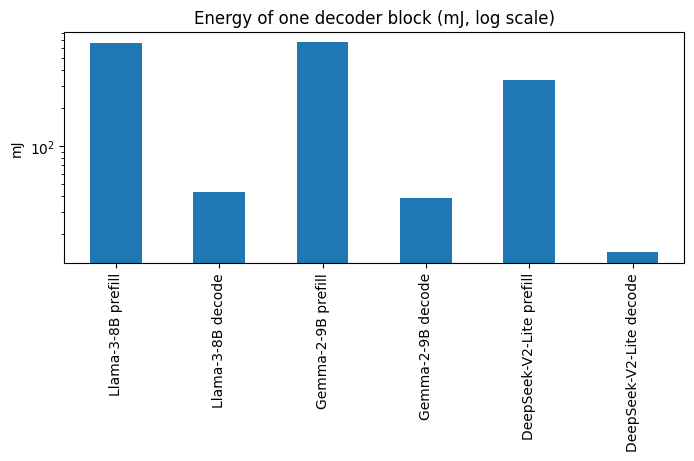

In [11]:
llm = pd.DataFrame([row(k, v) for k, v in reps.items() if "prefill" in k or "decode" in k])
display(llm.drop(columns=["total_pJ"]))
ax = llm.set_index("design / workload")["total_pJ"].div(1e9).plot.bar(figsize=(8, 3), legend=False, logy=True,
                                                                     title="Energy of one decoder block (mJ, log scale)")
ax.set_xlabel(""); ax.set_ylabel("mJ");

### 6.1 Prefill against decode: the same weights, 512 times less work

The Llama block in prefill costs 666.2 mJ for 512 tokens; in decode it costs
42.9 mJ for one token. Per token, decode is 33 times more expensive. The
reason is reuse, and you can read it off two counters.

In [12]:
pre, dec = reps["Llama-3-8B prefill"], reps["Llama-3-8B decode"]
def dram_rows(rep):
    return {r["label"]: r["pct"] for r in rep["dram_breakdown"]["rows"]}
pd.DataFrame([
    {"phase": "prefill (512 tokens)", "useful MACs": f"{pre['efficiency']['mac_ops']:.3g}", "DRAM %": pre["npu_dram_split"]["dram_pct"],
     "arrays %": round(sum(c["energy_pct"] for c in pre["components"] if c["name"].endswith(".pe")), 1),
     **{k: f"{v}%" for k, v in dram_rows(pre).items()}},
    {"phase": "decode (1 token)", "useful MACs": f"{dec['efficiency']['mac_ops']:.3g}", "DRAM %": dec["npu_dram_split"]["dram_pct"],
     "arrays %": round(sum(c["energy_pct"] for c in dec["components"] if c["name"].endswith(".pe")), 1),
     **{k: f"{v}%" for k, v in dram_rows(dec).items()}},
])

,phase,useful MACs,DRAM %,arrays %,Row activation (ACT+PRE),Transfer — read,Transfer — write,Refresh
0,prefill (512 tokens),1.14e+11,12.1,86.4,26.3%,62.3%,7.0%,4.5%
1,decode (1 token),2.23e+08,90.7,3.4,30.8%,64.2%,0.2%,4.9%


**Why DRAM takes over in decode.** Every GEMM of the block reads its whole
weight matrix from DRAM once. In prefill each weight is then used for 512
input rows; in decode it is used for one. The weights of one block are about
870 MB in float32. Decode reads them once (0.9 GB in the log). Prefill reads
about twice that (1.8 GB), because the FFN weights are streamed once per
group of input rows. So prefill moves 2 times the bytes for 512 times the
MACs, and the DRAM energy per MAC is about 250 times higher in decode
(174 pJ against 0.7 pJ). The arrays, which were 86% of prefill, are 3% of
decode. The DRAM breakdown shows that most of the
decode DRAM energy is data transfer, and a third is row activation: a
matrix-vector product streams each row once with little row-buffer reuse.

**Why refresh appears.** Refresh energy is proportional to time, not to
work. Refresh is 5% of the DRAM energy in both phases, but DRAM is 91% of
the decode run and 12% of the prefill run, so refresh is 4% of the decode
energy and 0.5% of the prefill energy. Decode spends 3.8 M cycles on 223 M
MACs; the HBM refreshes all the while.

**What the arrays do in decode.** The occupancy of the GEMV kernels is
reported as 100%: TOGSim counts an array cycle as active only while input
rows stream through it, and a 1-row GEMV streams one row per weight tile.
The arrays are idle for the rest of the time, waiting for weights, and the
idle time costs leakage only (the `leak` column of the per-kernel table).
So the TPU-like NPU is not wasting PE energy in decode; it is waiting.

**What would change the picture.** Batching decode requests reuses each
weight across the batch and moves the ratio back toward prefill. A smaller
data type halves the DRAM bytes (section 7 shows what the hardware model
can and cannot do about that). The picture also holds only at this context
length: the 512-entry KV cache is 4 MB against 870 MB of weights. At tens of
thousands of tokens the KV reads of attention exceed the weight bytes, and
designs such as MLA or KV batching change the answer. That is also why the
MLA of DeepSeek shows no advantage in these runs.

### 6.2 Dense against MoE: fewer MACs, more expensive MACs

DeepSeek-V2-Lite activates 6 of 64 experts per token, so its block has far
fewer MACs per token than the dense blocks. But each expert GEMM in prefill
has only 48 rows.

In [13]:
ex_d = example("pytorchsim/tpu_like_fp32/deepseek_v2_lite/prefill")
occ_d = occupancy_table(texts["DeepSeek-V2-Lite prefill"], kernel_names(ex_d))
wd = windows_df(reps["DeepSeek-V2-Lite prefill"]).set_index("window")
occ_d["cycles"] = [int(wd.loc[k, "cycles"]) for k in occ_d["kernel"]]
occ_d["energy"] = [wd.loc[k, "total"] for k in occ_d["kernel"]]
occ_d["pJ per useful MAC"] = [round(float(wd.loc[k, "total_pJ"]) / m, 1) for k, m in zip(occ_d["kernel"], occ_d["useful MACs"])]
display(occ_d)
display(window_components(reps["DeepSeek-V2-Lite prefill"], "8_experts_up_gate"))
display(window_components(reps["DeepSeek-V2-Lite prefill"], "1_q_proj"))

,kernel,useful MACs,active PE cycles,occupancy %,cycles,energy,pJ per useful MAC
0,1_q_proj,3221225472,3227041792,99.8,139312,1.79e+04 µJ,5.5
1,2_kv_a_proj,603979776,671088640,90.0,54389,3.65e+03 µJ,6.0
2,3_kv_b_proj,1073741824,1073741824,100.0,61383,6.27e+03 µJ,5.8
3,4_attn_qk,805306368,1073741824,75.0,100308,5.29e+03 µJ,6.6
4,5_attn_av,536870912,538361856,99.7,76224,3.63e+03 µJ,6.8
5,6_o_proj,2147483648,2147483648,100.0,101607,1.2e+04 µJ,5.6
6,7_router,67108864,134217728,50.0,16117,517 µJ,7.7
7,8_experts_up_gate,17716740096,17730322432,99.9,4625367,1.51e+05 µJ,8.5
8,9_experts_down,8858370048,8865415168,99.9,3164956,8.19e+04 µJ,9.2
9,10_shared_up_gate,5905580032,5905580032,100.0,226925,3.3e+04 µJ,5.6


,component,energy
0,core0.array0.pe,4.48e+04 µJ
1,core0.array0.w_reg,10.9 µJ
2,core0.array1.pe,4.48e+04 µJ
3,core0.array1.w_reg,10.9 µJ
4,core0.vpu_spad,1.26e+03 µJ
5,core0.vrf,4.14 µJ
6,core0.vfu,8.29 µJ
7,core0.dma_q,297 µJ
8,core0.dma_addr,61.4 µJ
9,icnt_xbar,344 µJ


,component,energy
0,core0.array0.pe,8.14e+03 µJ
1,core0.array0.w_reg,185 nJ
2,core0.array1.pe,8.14e+03 µJ
3,core0.array1.w_reg,185 nJ
4,core0.vpu_spad,110 µJ
5,core0.vrf,639 nJ
6,core0.vfu,1.28 µJ
7,core0.dma_q,6.92 µJ
8,core0.dma_addr,1.43 µJ
9,icnt_xbar,8.02 µJ


**Why the expert GEMMs cost 8.5 to 9.2 pJ per MAC against 5.5 to 5.6 pJ for
the dense projections, although the array is full in both.** A
weight-stationary array amortizes each weight tile over the input rows that
stream through it. The dense projections stream 512 rows per weight tile; an
expert GEMM streams 48. So per MAC, the expert kernels fetch about 10 times
more weight bytes from DRAM, move them through the NoC buffers and the lane
scratchpads,
and load them into the array. Compare the two component tables above: the
`pe` energy per MAC is the same (2.5 pJ per array), while `dram_chan` goes
from 0.4 to 3.2 pJ per MAC and `vpu_spad` and `icnt_buf` grow by a similar
factor. The two expert kernels are 69% of the block's energy and 85% of its
cycles.

**Why the router costs more per MAC.** N = 64 output columns fill half of
the 128-column weight tile, so half of the active PE cycles are empty (the
occupancy table shows 50%). The empty PEs cost leakage only, but each weight
tile does half the MACs for the data it moves: 7.7 pJ per useful MAC. It is
small in absolute terms.

**Why decode is the same story for all three.** In decode every GEMM is a
GEMV, dense or expert. The expert GEMMs then have 1 row each and the dense
ones have 1 row: there is no difference in reuse, and all three blocks land
at 168 to 195 pJ per useful MAC with DRAM at 88 to 90%.

### 6.3 Gemma against Llama: the same energy for fewer MACs

The Gemma block has 9% fewer MACs than the Llama block (hidden 3584 instead
of 4096) but costs the same in prefill, 672.2 against 666.2 mJ.

In [14]:
g, l = reps["Gemma-2-9B prefill"], reps["Llama-3-8B prefill"]
wg, wl = windows_df(g).set_index("window"), windows_df(l).set_index("window")
pairs = ["1_q_proj", "3_attn_qk", "6_ffn_up_gate", "7_ffn_down"]
pd.DataFrame([{"kernel": k, "Gemma cycles": int(wg.loc[k, "cycles"]), "Llama cycles": int(wl.loc[k, "cycles"]),
               "Gemma energy": wg.loc[k, "total"], "Llama energy": wl.loc[k, "total"]} for k in pairs])

,kernel,Gemma cycles,Llama cycles,Gemma energy,Llama energy
0,1_q_proj,411821,345779,4.26e+04 µJ,4.78e+04 µJ
1,3_attn_qk,100824,152117,6.65e+03 µJ,7.26e+03 µJ
2,6_ffn_up_gate,5575632,3267126,3.5e+05 µJ,3.51e+05 µJ
3,7_ffn_down,2691664,1716468,1.73e+05 µJ,1.7e+05 µJ


**Why the FFN costs more per MAC on Gemma.** Its hidden size 3584 is 28
tiles of 128 and the FFN width 14336 is 112 tiles. For this shape, the
PyTorchSim autotuner picked a tiling that takes 1.7 times more cycles than
Llama's FFN for 0.9 times the MACs. The tiling streams the FFN weights
from DRAM 4.3 times (1.76 GB of reads for 411 MB of `up_gate` weights, in
the log) against 2.1 times on Llama (1.01 GB for 470 MB). The kernel waits
for DRAM, so the cycles grow while the arrays are active for fewer cycles,
and the longer run adds leakage and refresh. This is a mapping effect, not
a hardware one: a different tiling
would bring the Gemma FFN back to about the Llama cost per MAC. NPUWattch
reports the run it is given, so look at the cycle column before you draw a
hardware conclusion from a cost per MAC.

**Why DRAM is 20% instead of 12%.** Almost all of the extra DRAM energy
(135 against 81 mJ) is the FFN weight re-streaming above: the two FFN
kernels are 114 mJ of DRAM on Gemma against 59 mJ on Llama. The rest is
the `kv_proj` (its weights are 1.7 times larger, 4.1 against 1.8 mJ) and the
refresh of the longer run. The attention kernels themselves are cheaper on
Gemma, 6.2 pJ per MAC against 6.8 on Llama: both fill the array, but Gemma
has 16 query heads instead of 32, so `attn_qk` writes half the score bytes
(16.8 against 33.6 MB) for the same MACs.

**What the activation changes.** GeGLU needs a tanh, which is an SFU
operation like the exponent of SiLU; the `10_gelu_mul` kernel costs about
the same as Llama's `10_silu_mul`. The activation is 0.6% of the block
either way. (This kernel ran with PyTorchSim's functional mode off, because
tanh crashes its functional simulator; the folder README explains.)

## 7. The same runs with bf16 PEs

Notebook 1 changed the PE to bf16 by swapping `compound_components.yaml`.
The workload scripts take the same flag, so any run above can be re-priced
with the bf16 model. The simulator data stays float32; only the hardware
model changes.

In [15]:
ex = example("pytorchsim/tpu_like_fp32/llama3_8b/prefill")
text_bf16 = run(ex, "--compound-components", "../../../tpu_like_bf16/compound_components.yaml",
                "--report", "out_bf16/", log_name="console_bf16.txt")
rep_bf16 = report(ex, "out_bf16/report.json")
pd.DataFrame([row("Llama-3-8B prefill, fp32 PEs", reps["Llama-3-8B prefill"]),
              row("Llama-3-8B prefill, bf16 PEs", rep_bf16)]).drop(columns=["total_pJ"])

,design / workload,total energy,DRAM share %,area mm²,avg power,pJ / MAC,cycles,pJ / FLOP
0,"Llama-3-8B prefill, fp32 PEs",6.66e+05 µJ,12.1,53.197,88.3 W,5.85,7092273,2.92 pJ/FLOP
1,"Llama-3-8B prefill, bf16 PEs",2.68e+05 µJ,30.1,42.288,35.5 W,2.35,7092273,1.18 pJ/FLOP


**Why the total falls by 2.5× while the PE energy falls by 3.2×.** The PE
energy per MAC goes from 5.05 to 1.56 pJ, as in notebook 1. Everything else
keeps its float32 cost: the DRAM bytes, the scratchpad and NoC traffic, the
vector unit and its register file. Those were 14% of the fp32 run and are now
34% of the bf16 run (666.2 mJ against 267.9 mJ in total). This is the usual
lesson of a datapath change: the parts you did not change set the floor.

**What the model cannot do here.** A real bf16 kernel would also move half
the bytes. NPUWattch charges the byte counts the simulator recorded, so the
DRAM and NoC lines are an upper bound for a bf16 kernel. The bf16 README
says the same.

## Messages you will see

**Every time.** The same WARNING lines as in notebook 1 (`NW-8212` SRAM
macro layout, `NW-8111` register-file width, and `NW-6607` kernel-total
split between the arrays in every run that has a GEMM kernel). The INFO lines `NW-6014` (window names from
`kernels.yaml`), `NW-6217` (gem5 counts scaled by the tile graph),
`NW-6222` (useful MACs and array occupancy of each GEMM kernel), and
`NW-6225` (the elements of one SFU instruction, from the kernel MLIR) are
the ones this notebook reads its reasons from. In runs with non-MAC kernels,
`NW-6001` says that they use the data type of the MAC kernels. The INFO
line `NW-3107` is in every run: NPUWattch assumes clock gating, so idle
cycles cost leakage only.

**In some runs:**

| What you see | What it means | What to do |
| --- | --- | --- |
| `WARNING (NW-6201): <hash>: the kernel has no linalg.matmul ...` | A kernel without a GEMM (softmax, norm, activation, the layout kernels of a convolution) | Nothing. The window is marked `non_mac` and its vector and SFU work is charged |
| `WARNING (NW-6208): <hash>: the kernel has SFU operations and an unknown operand dtype ...` | A kernel whose MLIR does not give the operand type of its SFU operations (the softmax kernels of every LLM run, and `softmax/`) | Nothing. The SFU is charged at fp32, which is what the simulator ran |
| `WARNING (NW-6602/6603/6604): ... NPUWattch divides the ... between the cores by ...` | A multi-core run (`matmul_2048_2core/`): the log gives the DRAM fill and drain bytes and the push/pop counts as chip totals | Nothing. The split follows the MOVIN/MOVOUT instructions and the active cycles of each core |
| `WARNING (NW-6002): The run has no MAC kernel, so non-MAC kernels use an fp32 datapath.` | The whole run has no GEMM (`softmax/`) | Nothing. The data type the simulator ran is fp32 |
| `WARNING (NW-6218): <hash>: no tile graph file (*_tog.py) ...` | The kernel directory lacks the tile graph, so the gem5 counts are scaled by the COMP counts of the log | Copy the `*_tog.py` of the kernel into `outputs/<hash>/` (the tutorial roots have it) |
| `WARNING (NW-6221): <hash>: the operator '...' is not known ...` | NPUWattch cannot count the useful MACs of this operator | Every active PE cycle is charged as a MAC; the PE energy is an upper bound |
| `WARNING (NW-6015): <log>: the log has no entry in kernels.yaml ...` | A kernel that the names file does not list | Add the entry, or ignore it: the window keeps its hash |

In [16]:
show_summary(texts["Llama-3-8B prefill"])

INFO (NW-1902): Message summary: 0 CRITICAL, 0 ERROR, 13 WARNING, 45 INFO.
    NW-6201   WARNING  x6
    NW-6208   WARNING  x3
    NW-6607   WARNING  x1
    NW-8111   WARNING  x1
    NW-8212   WARNING  x2


Next: `03_timeloop_eyeriss.ipynb`.